<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FFishing-Zone-Prediction/notebooks/C2_fishing_zone_prediction/C2_6_compare_models.ipynb%09" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 – Notebook 6: Compare all models and choose the best

Reads the saved results of Notebooks 2–5 (no training, no GPU needed).

* Adds an **ensemble** (average of the deep models' calibrated predictions).
* **Selection rule:** the candidate (deep model or ensemble) with the highest **validation 2024 PR-AUC**
  is chosen; the **test 2025** scores are then reported for everything. Choosing on validation and
  reporting on test keeps the test year unseen.
* If a model notebook's seed check (Step 10) was run, its mean ± std is shown too.

## Step 1 – Connect Drive and load labels

In [19]:
from google.colab import drive
drive.mount('/content/drive')
import os
BASE = '/content/drive/MyDrive/C2_data'; OUT = f'{BASE}/results'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import glob, json, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
X = xr.open_dataset(f'{BASE}/datacube_0p25.nc')
ocean = X['depth'].isel(time=0).notnull().values
label = np.nan_to_num(X['fishing'].values)
LEADS = 3
def scores(prob, ids):
    rows = []
    for k in range(LEADS):
        y = label[ids + 1 + k][:, ocean].ravel(); p = np.clip(prob[:, k][:, ocean].astype('float32').ravel(), 1e-6, 1 - 1e-6)
        rows.append({'lead_day': k + 1, 'PR_AUC': average_precision_score(y, p),
                     'ROC_AUC': roc_auc_score(y, p), 'Brier': brier_score_loss(y, p)})
    return pd.DataFrame(rows).round(4)

## Step 2 – Ensemble of the deep models

In [21]:
deep = {'U-Net (space only)': 'unet', 'ConvLSTM (space + time)': 'convlstm', 'ConvGRU (space + time)': 'convgru'}
have = {lab: k for lab, k in deep.items()
        if os.path.exists(f'{OUT}/{k}_val_predictions.npz') and os.path.exists(f'{OUT}/{k}_test_predictions.npz')}
ENS = 'Ensemble (average of deep models)'
if len(have) >= 2:
    def avg(kind):
        zs = [np.load(f'{OUT}/{k}_{kind}_predictions.npz') for k in have.values()]
        common = sorted(set.intersection(*[set(z['ids'].tolist()) for z in zs]))
        ps = [z['mean'][np.searchsorted(z['ids'], common)].astype('float32') for z in zs]
        return np.mean(ps, 0), np.array(common)
    (pv, iv), (pt, it) = avg('val'), avg('test')
    v = scores(pv, iv); v.insert(0, 'model', ENS); v.to_csv(f'{OUT}/ensemble_val_scores.csv', index=False)
    s = scores(pt, it); s.insert(0, 'model', ENS); s.to_csv(f'{OUT}/ensemble_test_scores.csv', index=False)
    np.savez_compressed(f'{OUT}/ensemble_test_predictions.npz', mean=pt.astype('float16'), ids=it)
    json.dump(list(have.values()), open(f'{OUT}/ensemble_members.json', 'w'))
    print('Ensemble of:', list(have)); print(s.to_string(index=False))
else:
    print('Need at least 2 trained deep models for an ensemble.')

Ensemble of: ['U-Net (space only)', 'ConvLSTM (space + time)', 'ConvGRU (space + time)']
                            model  lead_day  PR_AUC  ROC_AUC  Brier
Ensemble (average of deep models)         1  0.4113   0.8517   0.06
Ensemble (average of deep models)         2  0.4114   0.8512   0.06
Ensemble (average of deep models)         3  0.4124   0.8509   0.06


## Step 3 – Comparison table

In [22]:
val  = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{OUT}/*_val_scores.csv'))],  ignore_index=True)
test = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{OUT}/*_test_scores.csv'))], ignore_index=True)
order = ['Climatology', 'Gradient Boosting', 'U-Net (space only)', 'ConvGRU (space + time)',
         'ConvLSTM (space + time)', ENS, 'Persistence (upper ref.)']
order = [m for m in order if m in set(test.model)] + [m for m in test.model.unique() if m not in order]

table = test.pivot(index='model', columns='lead_day', values='PR_AUC').reindex(order)
table.columns = [f'PR-AUC Day {c}' for c in table.columns]
table['PR-AUC mean'] = table.mean(axis=1)
table['ROC-AUC mean'] = test.groupby('model').ROC_AUC.mean()
table['Brier mean'] = test.groupby('model').Brier.mean()
table['val PR-AUC (2024)'] = val.groupby('model').PR_AUC.mean()
seed_col = {}
for lab, k in deep.items():
    f = f'{OUT}/{k}_seeds.csv'
    if os.path.exists(f):
        sd = pd.read_csv(f); seed_col[lab] = f'{sd.test_PR_AUC.mean():.4f} ± {sd.test_PR_AUC.std():.4f} (n={len(sd)})'
if seed_col: table['test PR-AUC, seeds (mean ± std)'] = pd.Series(seed_col)
rand = float(label[np.load(f'{OUT}/{next(iter(have.values()))}_test_predictions.npz')['ids'] + 1][:, ocean].mean()) if have else np.nan
print(f'TEST 2025  (random guessing PR-AUC ≈ {rand:.3f}; higher PR-AUC / ROC-AUC = better, lower Brier = better)')
print(table.round(4).to_string())
table.round(4).to_csv(f'{OUT}/model_comparison.csv')

TEST 2025  (random guessing PR-AUC ≈ 0.072; higher PR-AUC / ROC-AUC = better, lower Brier = better)
                                   PR-AUC Day 1  PR-AUC Day 2  PR-AUC Day 3  PR-AUC mean  ROC-AUC mean  Brier mean  val PR-AUC (2024) test PR-AUC, seeds (mean ± std)
model                                                                                                                                                                
Climatology                              0.4184        0.4184        0.4189       0.4186        0.8520      0.0602             0.5863                             NaN
Gradient Boosting                        0.4060        0.4063        0.4063       0.4062        0.8502      0.0581             0.5531                             NaN
U-Net (space only)                       0.3842        0.3839        0.3836       0.3839        0.8356      0.0608             0.5404           0.4004 ± 0.0026 (n=3)
ConvGRU (space + time)                   0.3829        0.3830        0

## Step 4 – Choose the best (by validation PR-AUC)

In [23]:
keys = {**deep, ENS: 'ensemble'}
cand = table.loc[[m for m in keys if m in table.index], 'val PR-AUC (2024)'].dropna()
best_label = cand.idxmax(); best_key = keys[best_label]
open(f'{OUT}/best_model.txt', 'w').write(best_key)
print('Validation PR-AUC of candidates:'); print(cand.round(4).to_string())
print(f'\nBEST: {best_label}  -> saved to results/best_model.txt (the demo uses it)')
print(f'Its test PR-AUC (2025): {table.loc[best_label, "PR-AUC mean"]:.4f}')
for ref in ['Climatology', 'Gradient Boosting']:
    if ref in table.index:
        print(f'  vs {ref}: {table.loc[best_label, "PR-AUC mean"] - table.loc[ref, "PR-AUC mean"]:+.4f}')

Validation PR-AUC of candidates:
model
U-Net (space only)                   0.5404
ConvLSTM (space + time)              0.5703
ConvGRU (space + time)               0.5493
Ensemble (average of deep models)    0.5830

BEST: Ensemble (average of deep models)  -> saved to results/best_model.txt (the demo uses it)
Its test PR-AUC (2025): 0.4117
  vs Climatology: -0.0069
  vs Gradient Boosting: +0.0055


## Step 5 – Charts for the report

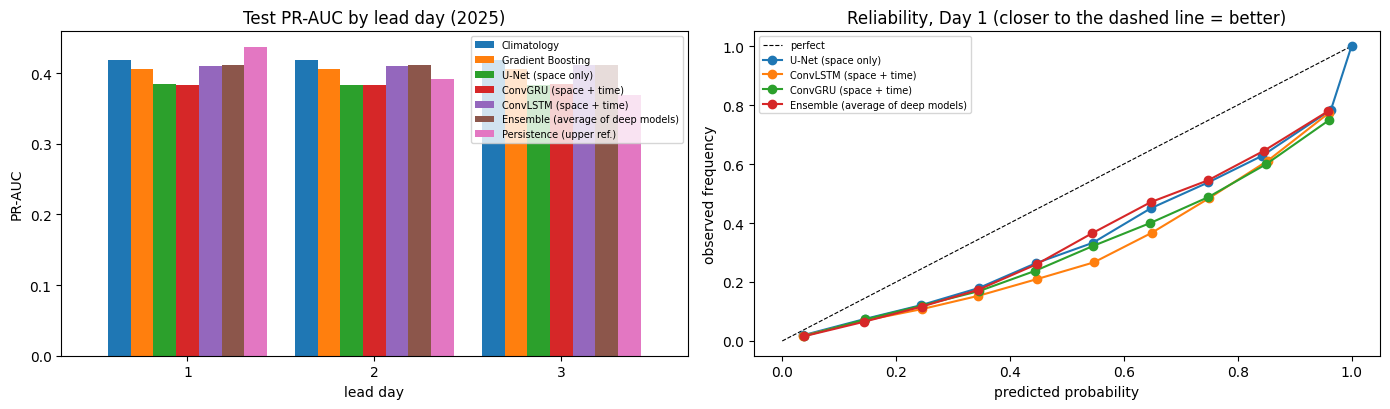

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
pr = test.pivot(index='lead_day', columns='model', values='PR_AUC')[order]
pr.plot(kind='bar', ax=ax[0], width=0.85)
ax[0].set_title('Test PR-AUC by lead day (2025)'); ax[0].set_xlabel('lead day'); ax[0].set_ylabel('PR-AUC')
ax[0].legend(fontsize=7); ax[0].tick_params(axis='x', rotation=0)
ax[1].plot([0, 1], [0, 1], 'k--', lw=0.8, label='perfect')
files = {lab: f'{OUT}/{k}_test_predictions.npz' for lab, k in deep.items()}
files[ENS] = f'{OUT}/ensemble_test_predictions.npz'
for lab, f in files.items():
    if not os.path.exists(f): continue
    z = np.load(f); p = z['mean'][:, 0][:, ocean].astype('float32').ravel(); y = label[z['ids'] + 1][:, ocean].ravel()
    b = np.digitize(p, np.linspace(0, 1, 11)) - 1
    r = pd.DataFrame({'b': b, 'p': p, 'y': y}).groupby('b').agg(pred=('p', 'mean'), obs=('y', 'mean'))
    ax[1].plot(r.pred, r.obs, 'o-', label=lab)
ax[1].set_xlabel('predicted probability'); ax[1].set_ylabel('observed frequency')
ax[1].set_title('Reliability, Day 1 (closer to the dashed line = better)'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT}/model_comparison.png', dpi=130); plt.show()

### How to read this (for the report)
* **Deep models vs Climatology / Gradient Boosting** → do ocean conditions add skill beyond the usual fishing grounds?
* **U-Net vs ConvLSTM/ConvGRU** → does the **time** dimension help beyond spatial patterns?
* **Ensemble** → does averaging models reduce errors?
* **Seeds (mean ± std)** → differences smaller than the std are not meaningful.
* **Persistence** uses live fishing data (not available to the real system) → upper reference only.